# Script for plotting 2d Variables
- plot for global mean metrics (Figure 2)
- plot for vertically integrated zonal mean cloud properties and precipitable water (Figure 6)

In [1]:
def weighted_mean(ds) :
    weights = np.cos(np.deg2rad(ds.lat))
    return ds.weighted(weights).mean(["lon","lat"])

In [ ]:
ref_exp = "iconml_amip_2mom_reference_60s"
SDN_60s_exp = "iconml_amip_superdropnet_sharma25_60s"
SDN_1x60s_exp = "iconml_amip_superdropnet_sharma25_60s_single_2ndtry"
DATA_DIR = "../data/"

In [4]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sn
import numpy as np

In [ ]:
dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')
dayslice_all = slice('2020-01-16', '2020-01-22T00:00:00.000000000')

In [ ]:
atm_2d_P1D_ref = xr.open_dataset(DATA_DIR + f"/{ref_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice)
atm_2d_P1D_SDN = xr.open_dataset(DATA_DIR + f"/{SDN_60s_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice)
atm_2d_P1D_SDN_1x60s = xr.open_dataset(DATA_DIR + f"/{SDN_1x60s_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice)

In [ ]:
atm_2d_P1D_ref_all_days = xr.open_dataset(DATA_DIR + f"/{ref_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice_all)
atm_2d_P1D_SDN_all_days = xr.open_dataset(DATA_DIR + f"/{SDN_60s_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice_all)
atm_2d_P1D_SDN_1x60s_all_days = xr.open_dataset(DATA_DIR + f"/{SDN_1x60s_exp}_atm_2d_P1D_all_1deg.nc").sel(time=dayslice_all)

In [13]:
variables=["ts","clt","cllvi","clivi","prw","qrvi"]
variable_names = ["Surface Pressure", "Surface Temperature", "Total Cloud Cover", "cloud liquid water path", "cloud ice path", "water vapor path", "rain water path"]

## Global Mean Metrics

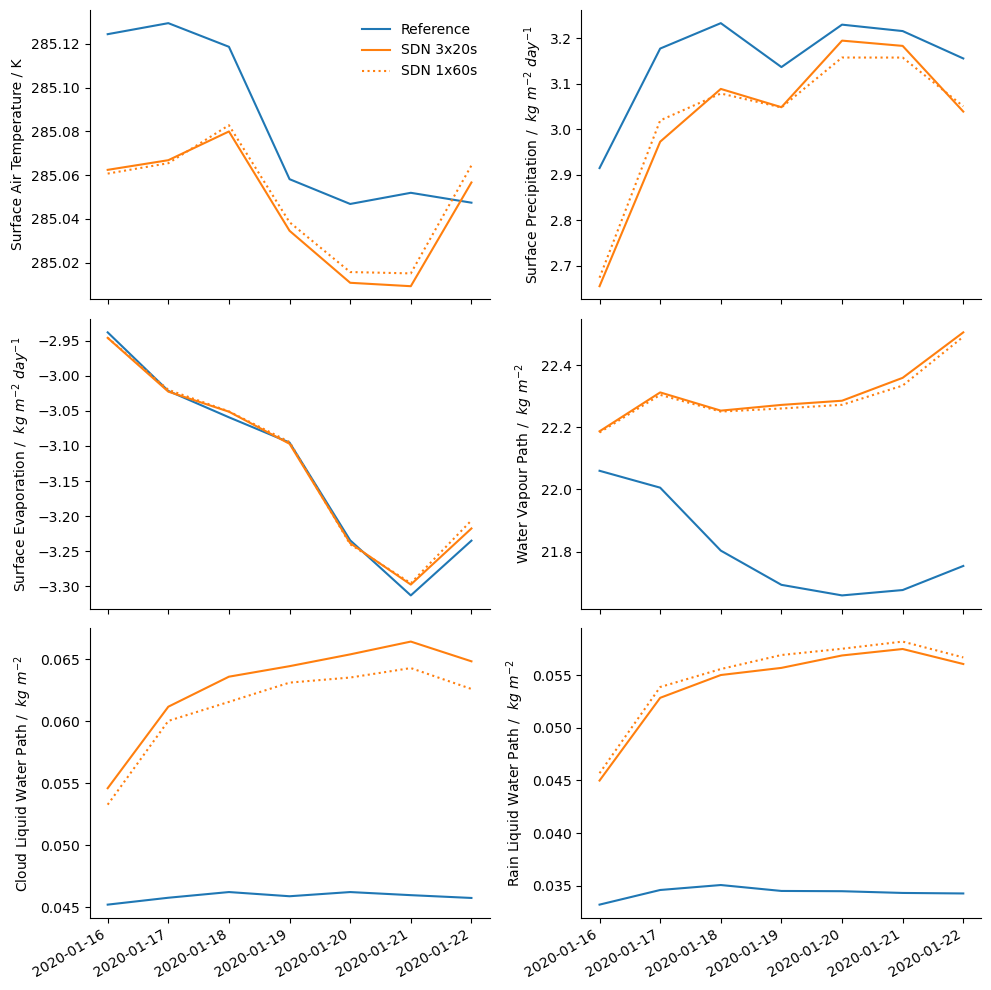

In [15]:
fig, axes = plt.subplots(3,2,figsize=(10, 10), sharex=True)
sn.despine(fig)
axes=axes.flatten()
ax=axes[0]
weighted_mean(atm_2d_P1D_ref_all_days.tas).plot(x="time", ax=axes[0], label="Reference")
weighted_mean(atm_2d_P1D_SDN_all_days.tas).plot(x="time", ax=axes[0], label="SDN 3x20s")
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.tas).plot(x="time", ax=axes[0], label="SDN 1x60s", color="tab:orange", ls=":")
#weighted_mean(atm_2d_P1D_SDN_old_all_days.tas).plot(x="time", ax=axes[0], label="SDN old constraints", color="black", ls=":")
#weighted_mean(atm_2d_P1D_ref_20s_all_days.tas).plot(x="time", ax=axes[0], label="ref 20s", color="black", ls="--")
ax.set_title("")
ax.set_ylabel("Surface Air Temperature / K")
ax.legend(frameon=False)

ax=axes[1]
weighted_mean(atm_2d_P1D_ref_all_days.pr*3600.*24.).plot(x="time", ax=ax)
weighted_mean(atm_2d_P1D_SDN_all_days.pr*3600.*24.).plot(x="time", ax=ax)
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.pr*3600.*24.).plot(x="time", ax=ax, color="tab:orange", ls=":")
ax.set_ylabel(r"Surface Precipitation / $ \ kg \ m^{-2}\ day^{-1}$")

ax=axes[2]
weighted_mean(atm_2d_P1D_ref_all_days.evspsbl*3600.*24.).plot(x="time", ax=ax)
weighted_mean(atm_2d_P1D_SDN_all_days.evspsbl*3600.*24.).plot(x="time", ax=ax)
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.evspsbl*3600.*24.).plot(x="time", ax=ax, color="tab:orange", ls=":")
ax.set_ylabel(r"Surface Evaporation / $ \ kg \ m^{-2}\ day^{-1}$")

weighted_mean(atm_2d_P1D_ref_all_days.prw).plot(x="time", ax=axes[3])
weighted_mean(atm_2d_P1D_SDN_all_days.prw).plot(x="time", ax=axes[3])
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.prw).plot(x="time", ax=axes[3], color="tab:orange", ls=":")
axes[3].set_ylabel(r"Water Vapour Path / $ \ kg \ m^{-2}$")

weighted_mean(atm_2d_P1D_ref_all_days.cllvi).plot(x="time", ax=axes[4])
weighted_mean(atm_2d_P1D_SDN_all_days.cllvi).plot(x="time", ax=axes[4])
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.cllvi).plot(x="time", ax=axes[4], color="tab:orange", ls=":")
axes[4].set_ylabel(r"Cloud Liquid Water Path / $ \ kg \ m^{-2}$")

weighted_mean(atm_2d_P1D_ref_all_days.qrvi).plot(x="time", ax=axes[5])
weighted_mean(atm_2d_P1D_SDN_all_days.qrvi).plot(x="time", ax=axes[5])
weighted_mean(atm_2d_P1D_SDN_1x60s_all_days.qrvi).plot(x="time", ax=axes[5], color="tab:orange", ls=":")
axes[5].set_ylabel(r"Rain Liquid Water Path / $ \ kg \ m^{-2}$")

for ax in axes :
    ax.set_xlabel("")

plt.tight_layout()

plt.savefig("../plots/global_mean_quantities.png")

## Cloud Properties

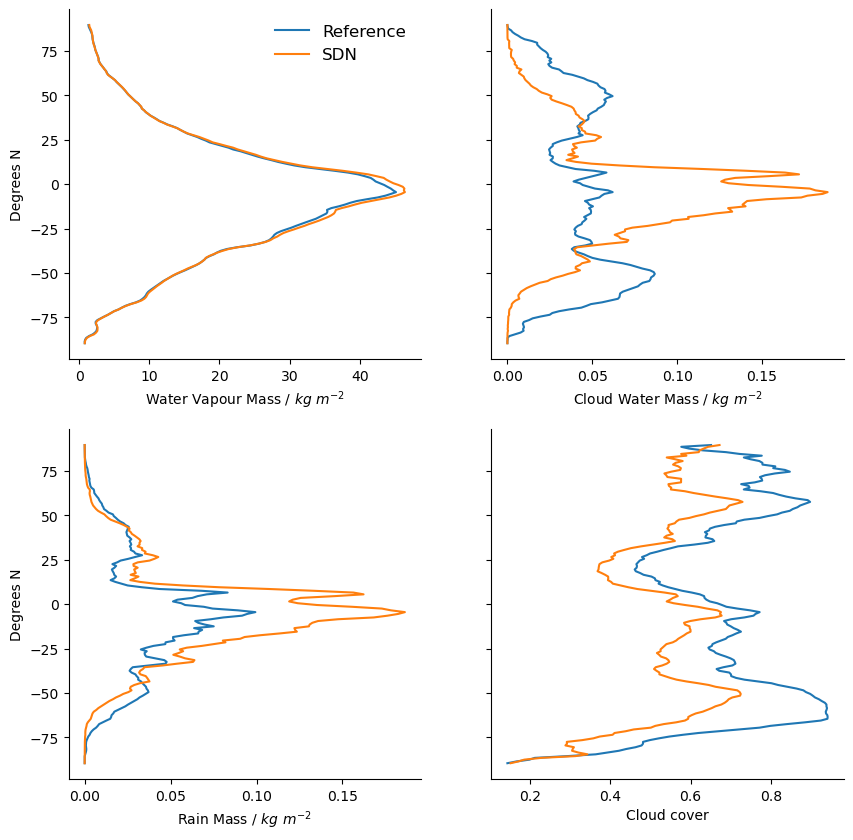

In [18]:
fig, axes = plt.subplots(2,2,figsize=(10, 10), sharey=True)

sn.despine(fig)

variables=["prw","cllvi","qrvi","clt"]
xlabels=['Water Vapour Mass / $kg \ m^{-2}$','Cloud Water Mass / $kg \ m^{-2}$','Rain Mass / $kg \ m^{-2}$', 'Cloud cover' ]

axes = axes.flatten()

for i in range(4) :
    atm_2d_P1D_ref[variables[i]].mean("lon").mean("time").plot(y="lat",ax=axes[i], label="Reference")

    #axes[0,i].set_xlim(-0.2,1)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    atm_2d_P1D_SDN[variables[i]].mean("lon").mean("time").plot(y="lat",ax=axes[i], label="SDN", color="tab:orange")
    #atm_2d_P1D_SDN_1x60s[variables[i]].mean("lon").mean("time").plot(y="lat",ax=axes[i],ls=":", label="SDN 1x60s",color="tab:orange")    
    
    #axes[1,i].set_xlim(-0.2,1)
    axes[i].set_xlabel(xlabels[i])
    axes[i].set_xlabel(xlabels[i])

axes[0].set_ylabel("Degrees N")
axes[2].set_ylabel("Degrees N")
axes[1].set_ylabel("")
axes[3].set_ylabel("")
#axes[0,0].set_ylabel("Degrees N")
#axes[1,0].set_ylabel("Degrees N")

axes[0].legend(frameon=False, fontsize=12)

fig.savefig("../plots/cloud_properties_zonmean.png")
